## Problem Statement

### Context

AllLife Bank is a mid-sized, fast-growing US-based financial institution that offers a range of retail banking services, including savings and checking accounts, fixed deposits, and personal loans. The bank’s business model is centered on building long-term customer relationships, expanding its retail footprint, and growing its loan portfolio to drive sustainable profitability through interest income.

It currently relies on a large base of liability customers (depositors) but faces a significant under-representation of asset customers (borrowers). To drive profitability through interest income, the bank must aggressively expand its loan portfolio by converting existing depositors into personal loan customers.

Last year’s pilot campaign achieved a 9% conversion rate, validating the potential of this strategy. However, to optimize marketing spend and improve efficiency, the retail marketing department requires a more data-driven approach. Enhancing the success ratio of these campaigns is critical for sustainable growth and maximizing customer lifetime value.

### Objective

The objective is to develop a predictive classification model that identifies patterns and key factors driving personal loan adoption among existing liability customers. By uncovering the demographic and behavioral drivers of loan conversion, the goal is to enable targeted segmentation and more precise marketing interventions that improve campaign conversion rates, optimize marketing spend, and enhance overall profitability through higher-quality loan portfolio growth.

### Data Dictionary

* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 sklearn-pandas==2.2.0 -q --user

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
# Importing libraries for data manipulation
import numpy as np
import pandas as pd

# Importing libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Importing libraries for splitting data
from sklearn.model_selection import train_test_split

# Importing libraries for model prediction
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Importing libraries for getting different metric scores
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Suppressing unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

## Loading the dataset

In [ ]:
# Mounting from Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Loading data set
df = pd.read_csv('/content/drive/MyDrive/Loan_Modelling.csv')

In [ ]:
# Making a copy of the original data
df_copy = df.copy()

## Data Overview

In [ ]:
# The first 5 rows of the data set
df_copy.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
# The last 5 rows of the data set
df_copy.tail()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


In [ ]:
# The number of rows and cols in the data set
df_copy.shape

(5000, 14)

There are 5000 rows and 14 cols.

In [ ]:
# The data types of different cols in the data set
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


All cols are ints except CCAvg, a float.

In [ ]:
# The statistical summary of the data set (needs to be transposed!)
df_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


In [ ]:
# Dropping ID col from the data set (it is redundant)
df_copy = df_copy.drop(['ID'], axis = 1)

## Data Preprocessing Part I

### Missing/Anomalous Value Treatment

In [ ]:
# Checking if rows are unique based on Experience
df_copy['Experience'].unique()

array([ 1, 19, 15,  9,  8, 13, 27, 24, 10, 39,  5, 23, 32, 41, 30, 14, 18,
       21, 28, 31, 11, 16, 20, 35,  6, 25,  7, 12, 26, 37, 17,  2, 36, 29,
        3, 22, -1, 34,  0, 38, 40, 33,  4, -2, 42, -3, 43])

In [ ]:
# Checking for negative values in Experience
df_copy[df_copy['Experience'] < 0]['Experience'].unique()

array([-1, -2, -3])

In [ ]:
# Correcting these mistakes
df_copy['Experience'].replace(-1, 1, inplace = True)
df_copy['Experience'].replace(-2, 2, inplace = True)
df_copy['Experience'].replace(-2, 2, inplace = True)

In [ ]:
# Checking if rows are unique based on Education
df_copy['Education'].unique()

array([1, 2, 3])

Negative values for Experience make no sense, hence why the values were corrected in this step.

### Feature Engineering

In [ ]:
# Checking the num of unique ZIP codes
df_copy['ZIPCode'].nunique()

467

There are 467 unique ZIP codes.

In [ ]:
# Converting ZIPCode to category by first two digits
df_copy['ZIPCode'] = df_copy['ZIPCode'].astype(str)
df_copy['ZIPCode'] = df_copy['ZIPCode'].str[0:2]
df_copy['ZIPCode'] = df_copy['ZIPCode'].astype('category')

In [ ]:
# Converting data type of categorical features to "category"
cats = ['Education', 'Personal_Loan', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard', 'ZIPCode']
df_copy[cats] = df_copy[cats].astype('category')

## Exploratory Data Analysis.

EDA is a critical step in any data project used to investigate and understand the data before model construction.

The following questions serve as a starting point to help you approach the analysis and generate initial insights:

**Questions**:
1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their education?
5. How does a customer's interest in purchasing a loan vary with their age?

**[IMPORTANT]** Beyond the Basics: Please note that these are guiding questions only. To receive full points for this rubric section, you are expected to perform a thorough analysis that goes beyond these specific questions to uncover deeper trends and relationships within the data.

### Univariate EDA

In [ ]:
# Defining hist_box function
def hist_box(data, feature, figsize = (12, 7), kde = False, bins = None):
  f2, (ax_box2, ax_hist2) = plt.subplots(
    nrows = 2,
    sharex = True,
    gridspec_kw = {"height_ratios": (0.25, 0.75)},
    figsize = figsize,
  ) # The two subplots
  sns.boxplot(
    data = data, x = feature, ax = ax_box2, showmeans = True, color = 'violet'
  ) # The boxplot
  sns.histplot(
    data = data, x = feature, kde = kde, ax = ax_hist2, bins = bins, palette = 'winter'
  ) if bins else sns.histplot(
    data = data, x = feature, kde = kde, ax = ax_hist2
  ) # The histogram
  ax_hist2.axvline(
    data[feature].mean(), color = 'green', linestyle = '--'
  ) # The histogram's mean
  ax_hist2.axvline(
    data[feature].median(), color = 'black', linestyle = '-'
  ) # The histogram's median

In [ ]:
# Defining the lab_bar function
def lab_bar(data, feature, perc = False, n = None):
  total = len(data[feature])
  count = data[feature].nunique()
  if n is None:
    plt.figure(figsize = (count + 1, 5))
  else:
    plt.figure(figsize = (n + 1, 5))

  plt.xticks(rotation = 90, fontsize = 15)
  ax = sns.countplot(
    data = data,
    x = feature,
    palette = 'Paired',
    order = data[feature].value_counts().index[:n].sort_values(),
  )

  for p in ax.patches:
    if perc == True:
      label = '{:.1f}%'.format(100 * p.get_height() / total) # % of each class of the category
    else:
      label = p.get_height() # count of each level of the category

    x = p.get_x() + p.get_width() / 2 # width of the plot
    y = p.get_height() # height of the plot

    ax.annotate(
      label,
      (x, y),
      ha = 'center',
      va = 'center',
      size = 12,
      xytext = (0, 5),
      textcoords = 'offset points',
    ) # annotate the percentage

  plt.show() # show the plot

#### Age

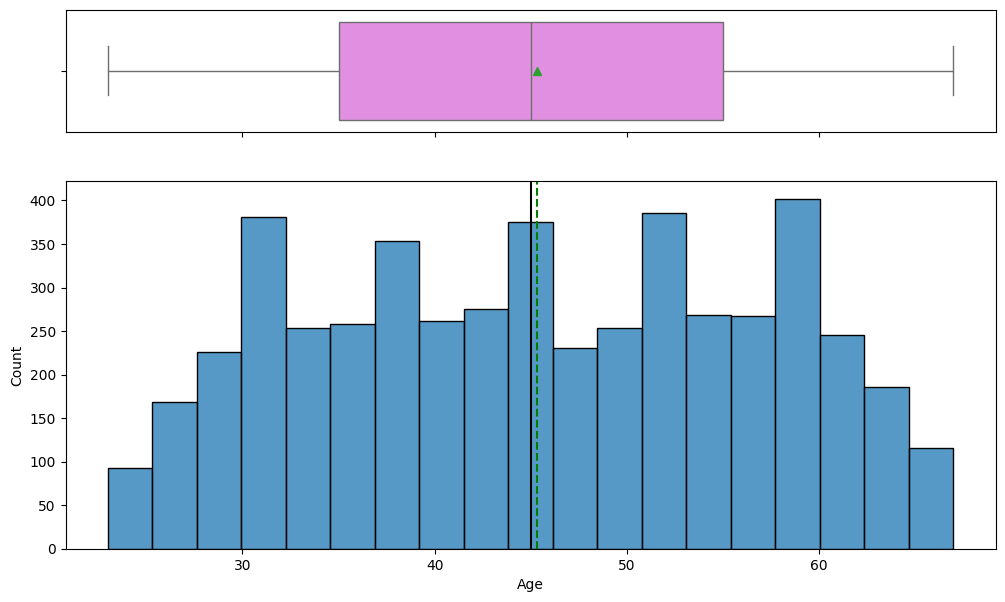

In [ ]:
# The histogram and boxplot for Age
hist_box(df_copy, 'Age')

The distribution appears to be somehwat symmetrical, with a mean of approximately 45.

#### Q1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?

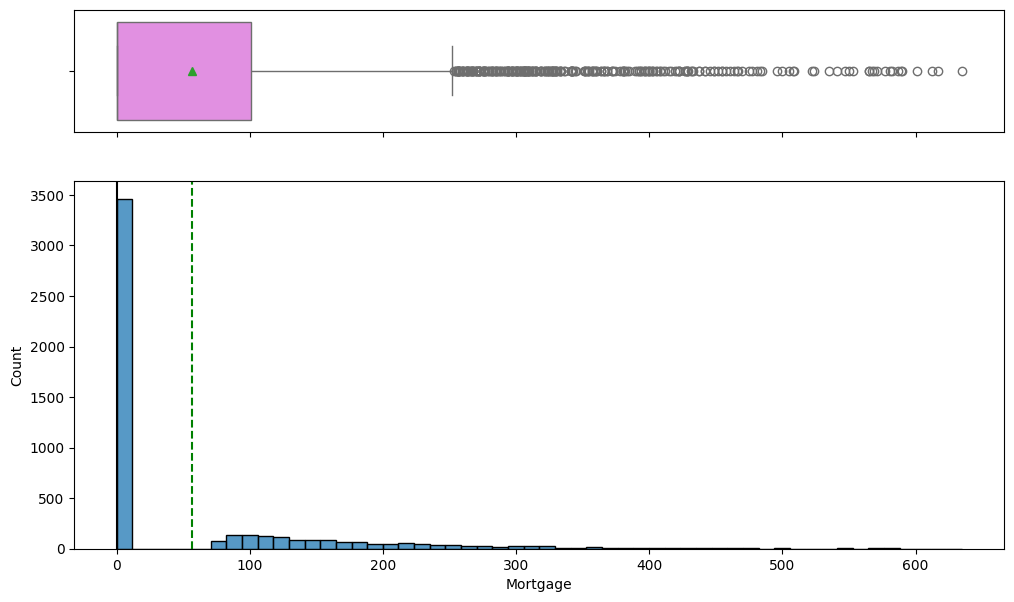

In [ ]:
# The histogram and boxplot for Mortgage
hist_box(df_copy, 'Mortgage')

The distribution appears to be heavily right-skewed, with numerous outliers.

#### Experience

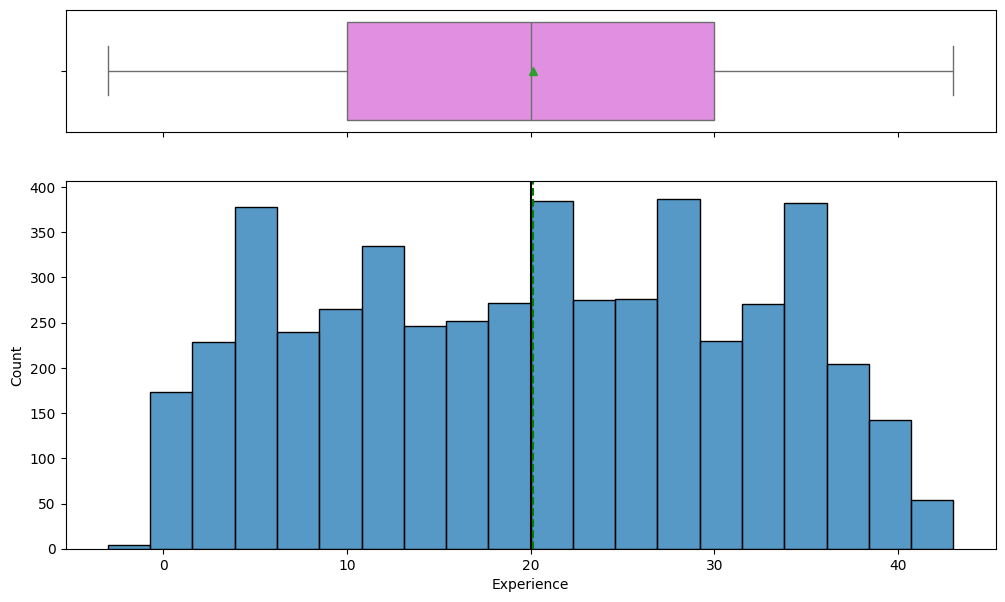

In [ ]:
# The histogram and boxplot for Experience
hist_box(df_copy, 'Experience')

The distribution appears to be somewhat symmetrical, with a mean of approximately 20.

#### Income

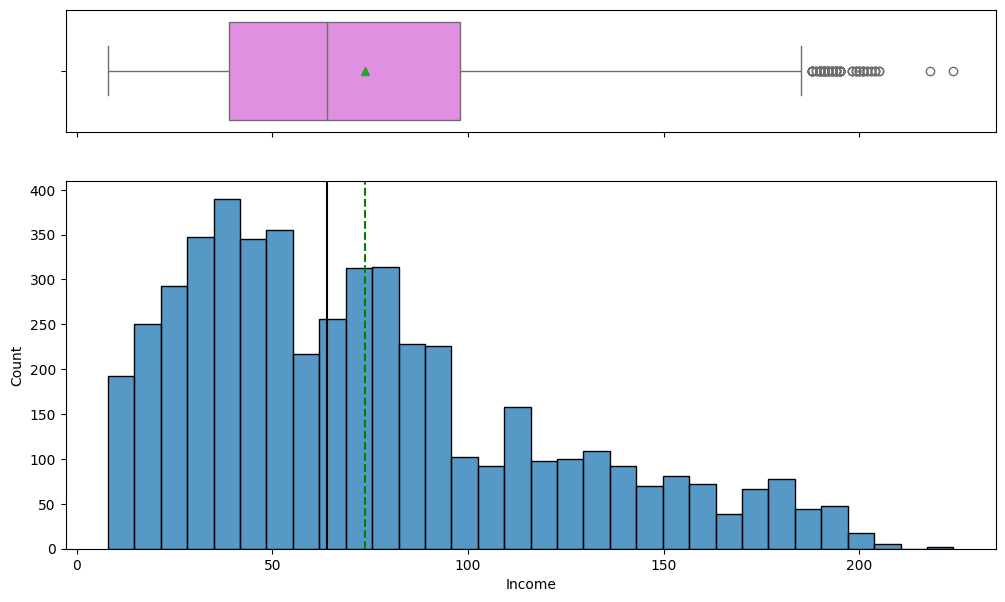

In [ ]:
# The histogram and boxplot for Income
hist_box(df_copy, 'Income')

The distribution appears to be right-skewed, with a good number of outliers.

#### CCAvg

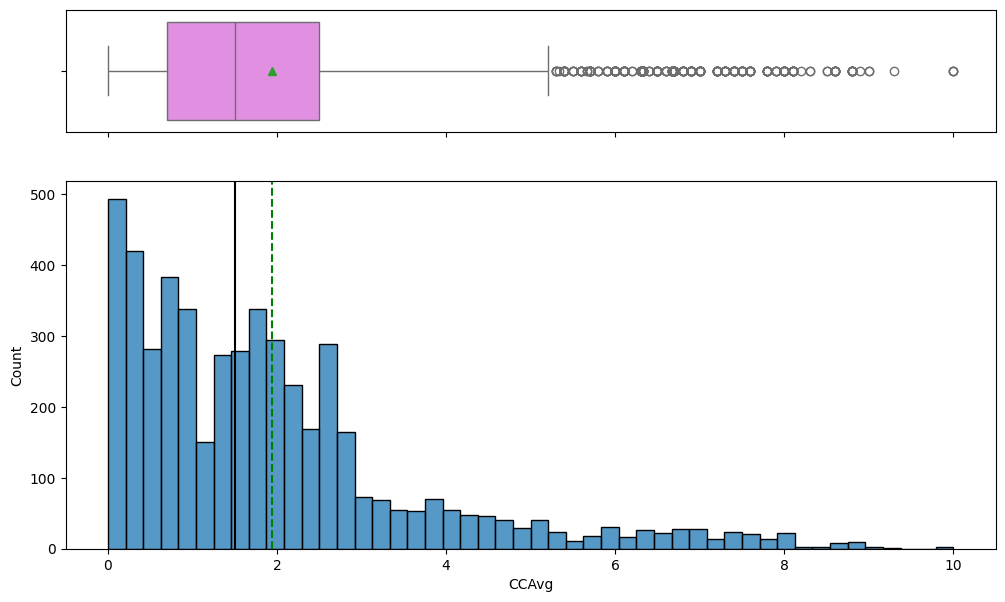

In [ ]:
# The histogram and boxplot for CCAvg
hist_box(df_copy, 'CCAvg')

The distribution appears to be heavily right-skewed, with numerous outliers.

#### Family

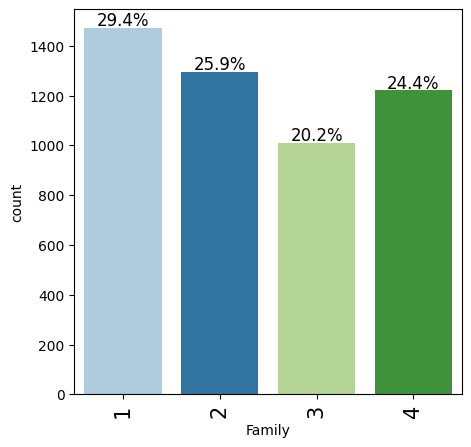

In [ ]:
# The labeled barplot for Family
lab_bar(df_copy, 'Family', perc = True)

Families of size 1 are the most prevalent at 29.4%, while families of size 3 are the least prevalent at 20.2%.

#### Q2. How many customers have credit cards?

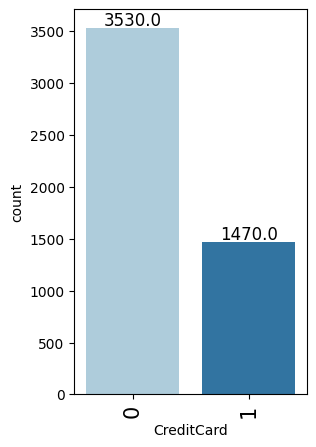

In [ ]:
# The labeled barplot for CreditCard
lab_bar(df_copy, 'CreditCard')

1470 customers use credit cards issued by other banks, while 3530 customers use credit cards issued by the original bank.

#### Education

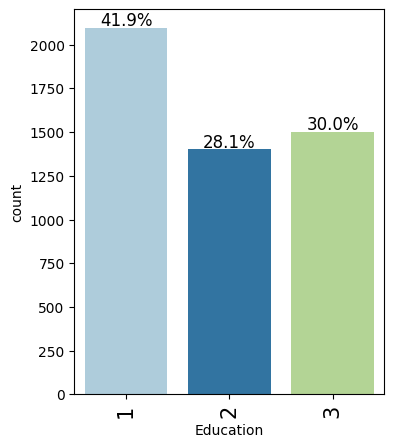

In [ ]:
# The labeled barplot for Education
lab_bar(df_copy, 'Education', perc = True)

41.9% of customers are undergrads, while the rest are either grads or professionals.

#### Securities_Account

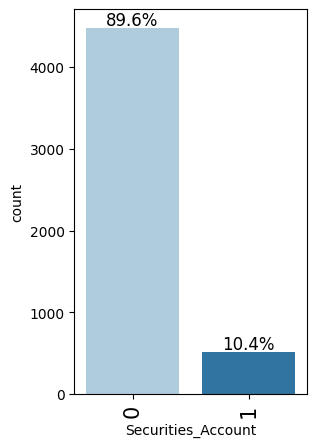

In [ ]:
# The labeled barplot for Securities_Account
lab_bar(df_copy, 'Securities_Account', perc = True)

89.6% of customers do not have a securities account.

#### CD_Account

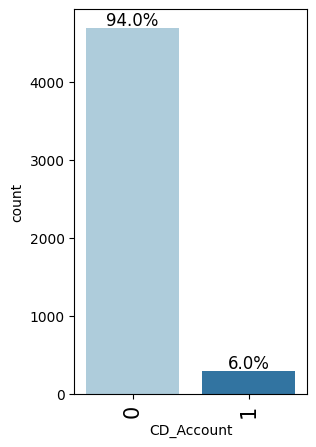

In [ ]:
# The labeled barplot for CD_Account
lab_bar(df_copy, 'CD_Account', perc = True)

94.0% of customers do not have CD accounts.

#### Online

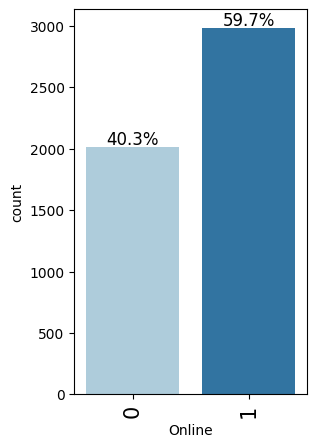

In [ ]:
# The labeled barplot for Online
lab_bar(df_copy, 'Online', perc = True)

59.7% of customers do use Internet banking facilities, while the rest do not.

#### ZIPCode

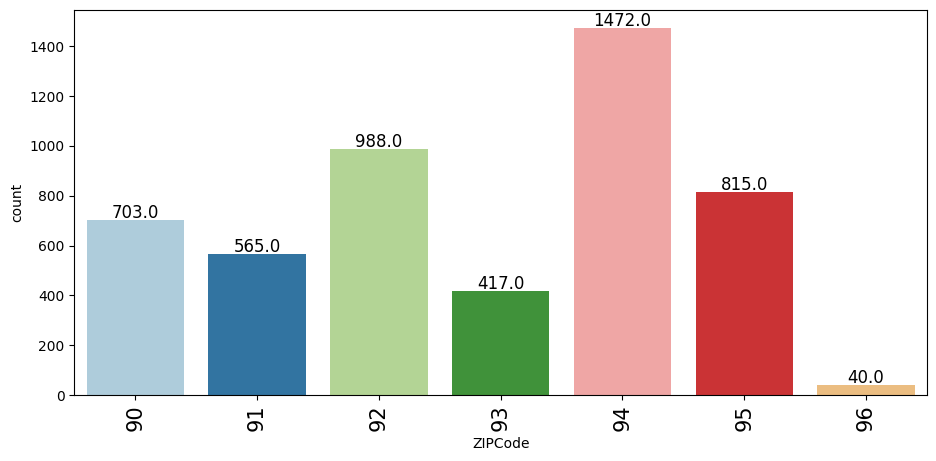

In [ ]:
# The labeled barplot for ZIPCode
lab_bar(df_copy, 'ZIPCode', n = 10)

ZIP codes starting with 94 are the most prevalent at 1472, while ZIP codes starting with 96 are the least prevalent at 40.

### Bivariate EDA

In [ ]:
# Defining stack_bar function
def stack_bar(data, predictor, target):
  count = data[predictor].nunique()
  sorter = data[target].value_counts().index[-1]
  tab1 = pd.crosstab(data[predictor], data[target], margins = True).sort_values(
    by = sorter, ascending = False
  )
  print(tab1)
  print('-' * 120)
  tab = pd.crosstab(data[predictor], data[target], normalize = 'index').sort_values(
    by = sorter, ascending = False
  )
  tab.plot(kind = 'bar', stacked = True, figsize = (count + 5, 5))
  plt.legend(
      loc = 'lower left', frameon = False,
  )
  plt.legend(loc = 'upper left', bbox_to_anchor = (1, 1))
  plt.show()

In [ ]:
# Defining dist_plot_wrt_target function
def dist_plot_wrt_target(data, predictor, target):
  fig, axs = plt.subplots(2, 2, figsize = (12, 10))
  target_uniq = data[target].unique()
  axs[0, 0].set_title('Distribution of target for target = ' + str(target_uniq[0]))
  sns.histplot(
    data = data[data[target] == target_uniq[0]],
    x = predictor,
    kde = True,
    ax = axs[0, 0],
    color = 'teal',
    stat = 'density'
  )
  axs[0, 1].set_title('Distribution of target for target = ' + str(target_uniq[1]))
  sns.histplot(
    data = data[data[target] == target_uniq[1]],
    x = predictor,
    kde = True,
    ax = axs[0, 1],
    color = 'orange',
    stat = 'density'
  )
  axs[1, 0].set_title('Boxplot wrt target')
  sns.boxplot(
    data = data,
    x = target,
    y = predictor,
    ax = axs[1, 0],
    palette = 'gist_rainbow'
  )
  axs[1, 1].set_title('Boxplot (no outliers) wrt target')
  sns.boxplot(
    data = data,
    x = target,
    y = predictor,
    ax = axs[1, 1],
    showfliers = False,
    palette = 'gist_rainbow'
  )
  plt.tight_layout()
  plt.show()

#### Q3. What are the attributes that have a strong correlation with the target attribute (personal loan)?

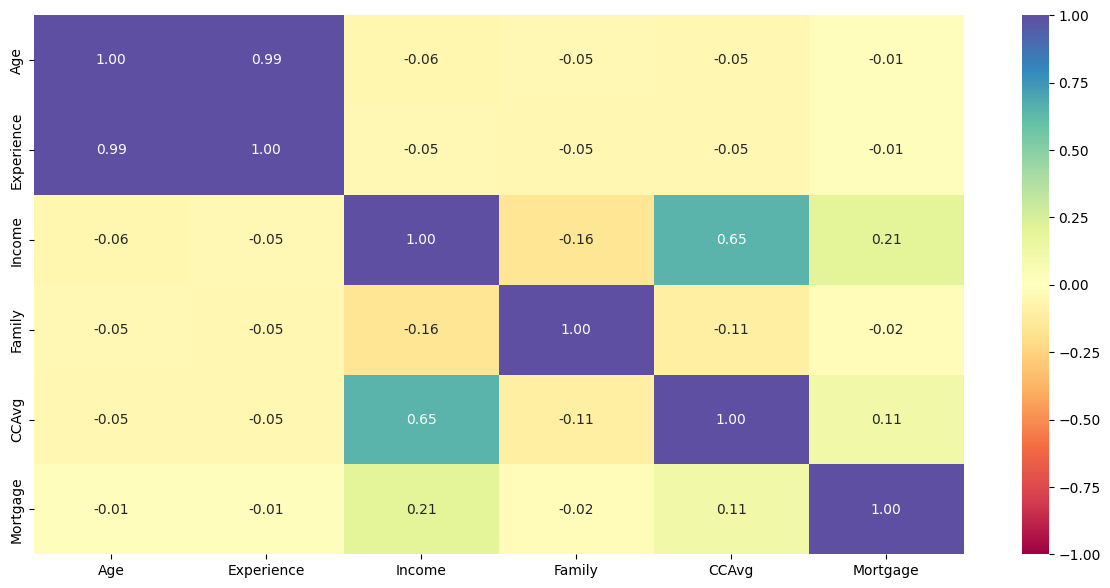

In [ ]:
# The heatmap between attributes
plt.figure(figsize = (15, 7))
sns.heatmap(df_copy.corr(numeric_only = True), annot = True, vmin = -1, vmax = 1, fmt = '.2f', cmap = 'Spectral')
plt.show()

Age and Experience are strongly positively correlated at 0.99, while Income and CCavg are moderately positively correlated at 0.65. Everything else is weakly correlated.

#### Q4. How does a customer's interest in purchasing a loan vary with their education?

Personal_Loan     0    1   All
Education                     
All            4520  480  5000
3              1296  205  1501
2              1221  182  1403
1              2003   93  2096
------------------------------------------------------------------------------------------------------------------------


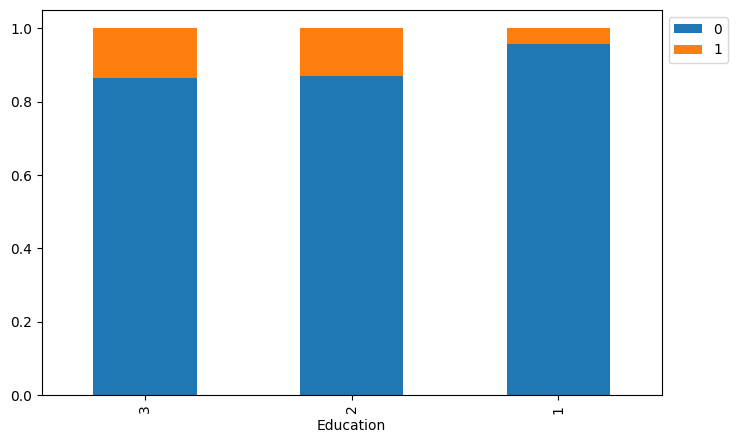

In [ ]:
# The stacked barplot for Personal_Loan and Education
stack_bar(df_copy, 'Education', 'Personal_Loan')

Education         1     2     3   All
Personal_Loan                        
All            2096  1403  1501  5000
0              2003  1221  1296  4520
1                93   182   205   480
------------------------------------------------------------------------------------------------------------------------


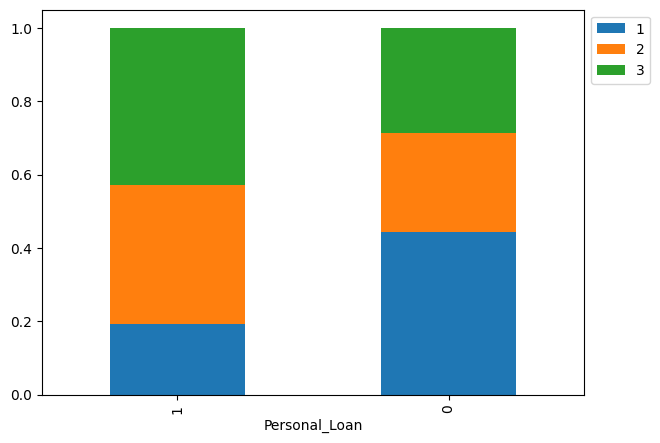

In [ ]:
# Vice versa
stack_bar(df_copy, 'Personal_Loan', 'Education')

Across all Education levels, there are more people without personal loans than people with personal loans. Additionally, most of those without personal loans are undergrads, while most of those with personal loans are professionals.

#### Personal_Loan vs Family

Personal_Loan     0    1   All
Family                        
All            4520  480  5000
4              1088  134  1222
3               877  133  1010
1              1365  107  1472
2              1190  106  1296
------------------------------------------------------------------------------------------------------------------------


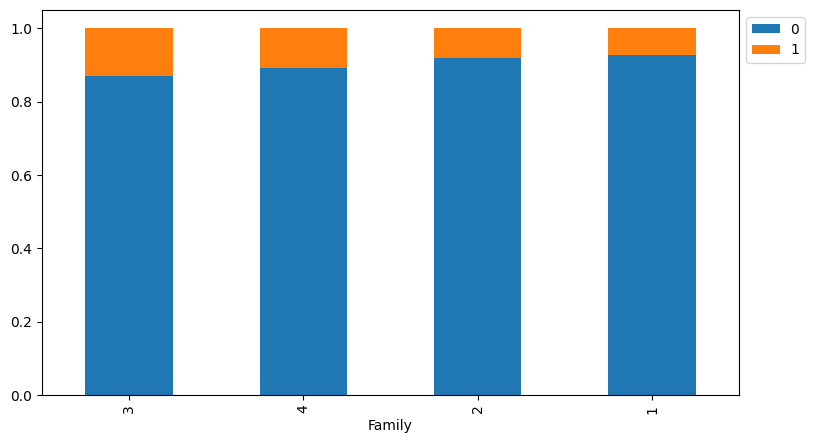

In [ ]:
# The stacked barplot for Personal_Loan and Family
stack_bar(df_copy, 'Family', 'Personal_Loan')

Family            1     2     3     4   All
Personal_Loan                              
All            1472  1296  1010  1222  5000
0              1365  1190   877  1088  4520
1               107   106   133   134   480
------------------------------------------------------------------------------------------------------------------------


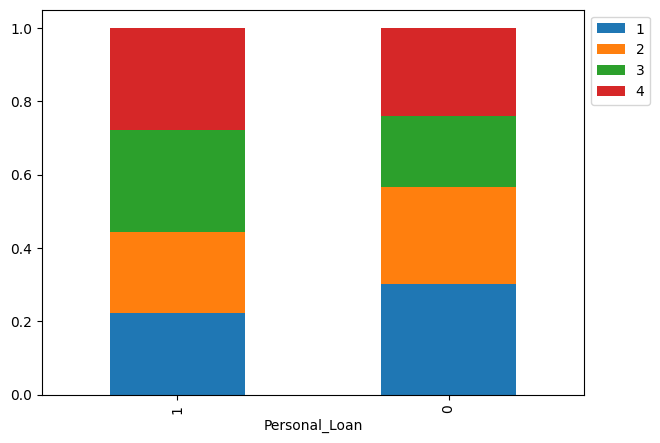

In [ ]:
# Vice versa
stack_bar(df_copy, 'Personal_Loan', 'Family')

Most families do not have personal loans, but most of the families without personal loans are families of size 1, and most of the families with personal loans are families of size 3.

#### Personal_Loan vs Securities_Account

Securities_Account     0    1   All
Personal_Loan                      
All                 4478  522  5000
0                   4058  462  4520
1                    420   60   480
------------------------------------------------------------------------------------------------------------------------


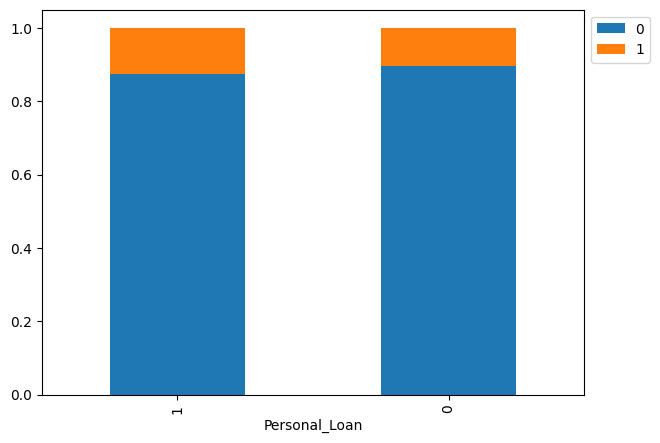

In [ ]:
# The stacked barplot for Personal_Loan and Securities_Account
stack_bar(df_copy, 'Personal_Loan', 'Securities_Account')

Most people, whether or not they have personal loans, do not have securities accounts.

#### Personal_Loan vs CD_Account

CD_Account        0    1   All
Personal_Loan                 
All            4698  302  5000
0              4358  162  4520
1               340  140   480
------------------------------------------------------------------------------------------------------------------------


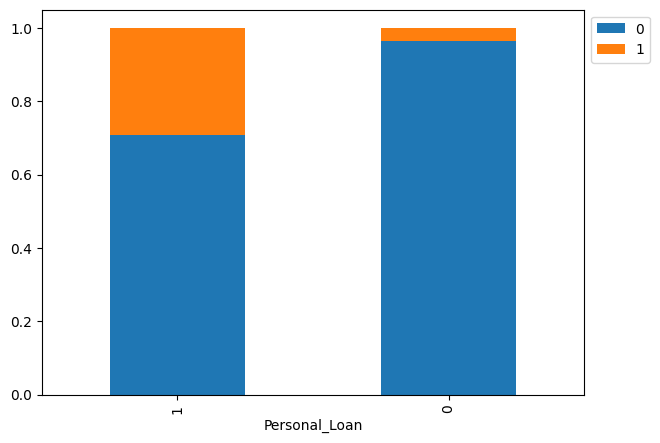

In [ ]:
# The stacked barplot for Personal_Loan and CD_Account
stack_bar(df_copy, 'Personal_Loan', 'CD_Account')

Though most people, whether or not they have personal loans, do not have CD accounts, a sizable portion of those with personal loans do, in fact, have CD accounts.

#### Personal_Loan vs Online

Online            0     1   All
Personal_Loan                  
All            2016  2984  5000
0              1827  2693  4520
1               189   291   480
------------------------------------------------------------------------------------------------------------------------


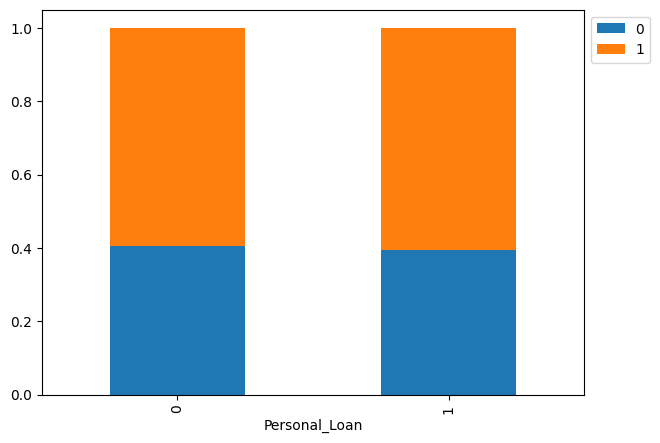

In [ ]:
# The stacked barplot for Personal_Loan and Online
stack_bar(df_copy, 'Personal_Loan', 'Online')

A majority of those with or without personal loans do use online facilities.

#### Personal_Loan vs CreditCard

CreditCard        0     1   All
Personal_Loan                  
All            3530  1470  5000
0              3193  1327  4520
1               337   143   480
------------------------------------------------------------------------------------------------------------------------


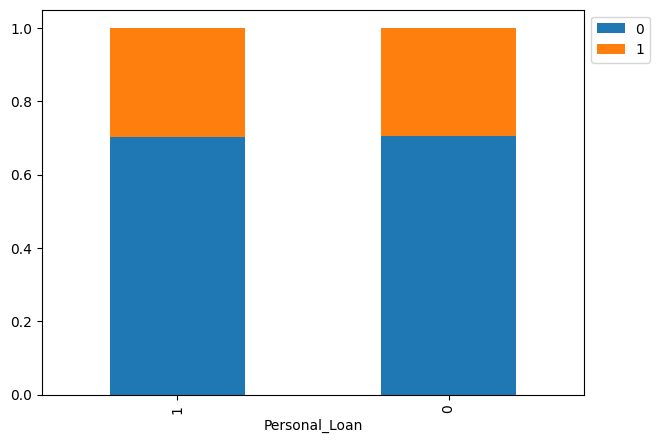

In [ ]:
# The stacked barplot for Personal_Loan and CreditCard
stack_bar(df_copy, 'Personal_Loan', 'CreditCard')

A majority of those with or without personal loans have credit cards only with the original bank, while a minority of each have other credit cards.

#### Personal_Loan vs ZIPCode

Personal_Loan     0    1   All
ZIPCode                       
All            4520  480  5000
94             1334  138  1472
92              894   94   988
95              735   80   815
90              636   67   703
91              510   55   565
93              374   43   417
96               37    3    40
------------------------------------------------------------------------------------------------------------------------


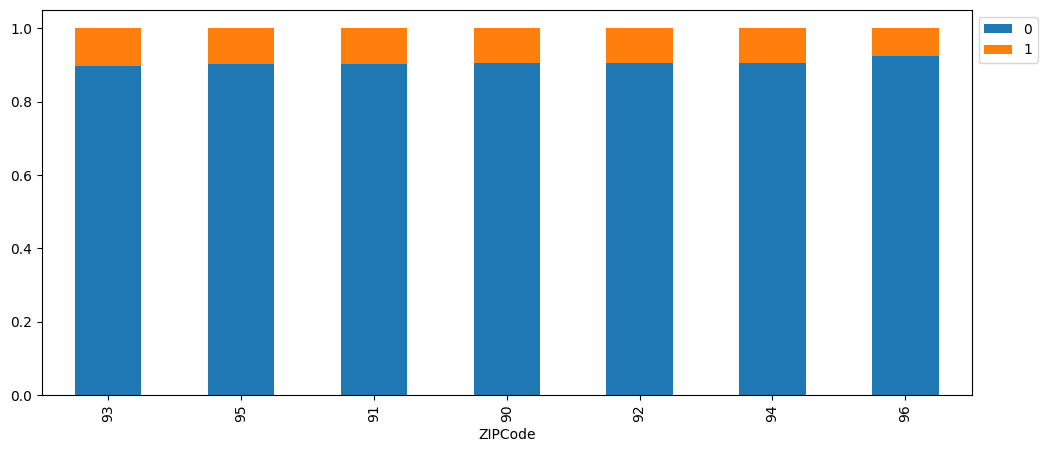

In [ ]:
# The stacked barplot for Personal_Loan and ZIPCode
stack_bar(df_copy, 'ZIPCode', 'Personal_Loan')

ZIPCode         90   91   92   93    94   95  96   All
Personal_Loan                                         
All            703  565  988  417  1472  815  40  5000
0              636  510  894  374  1334  735  37  4520
1               67   55   94   43   138   80   3   480
------------------------------------------------------------------------------------------------------------------------


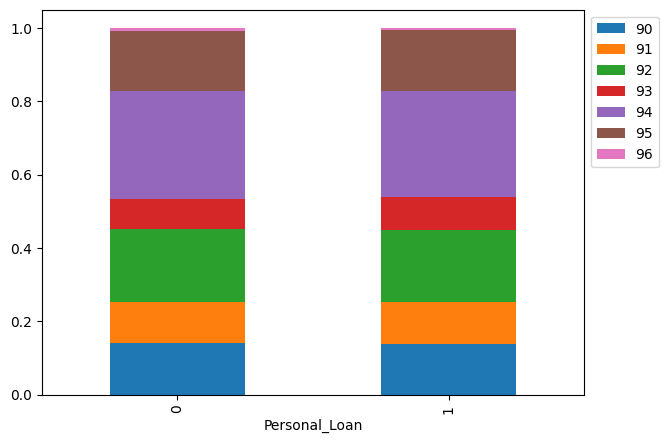

In [ ]:
# Vice versa
stack_bar(df_copy, 'Personal_Loan', 'ZIPCode')

Throughout different ZIP codes, a majority of them do not have personal loans. Additionally, the stacks of the vice versa stacked barplot appear to be balanced.

#### Q5. How does a customer's interest in purchasing a loan vary with their age?

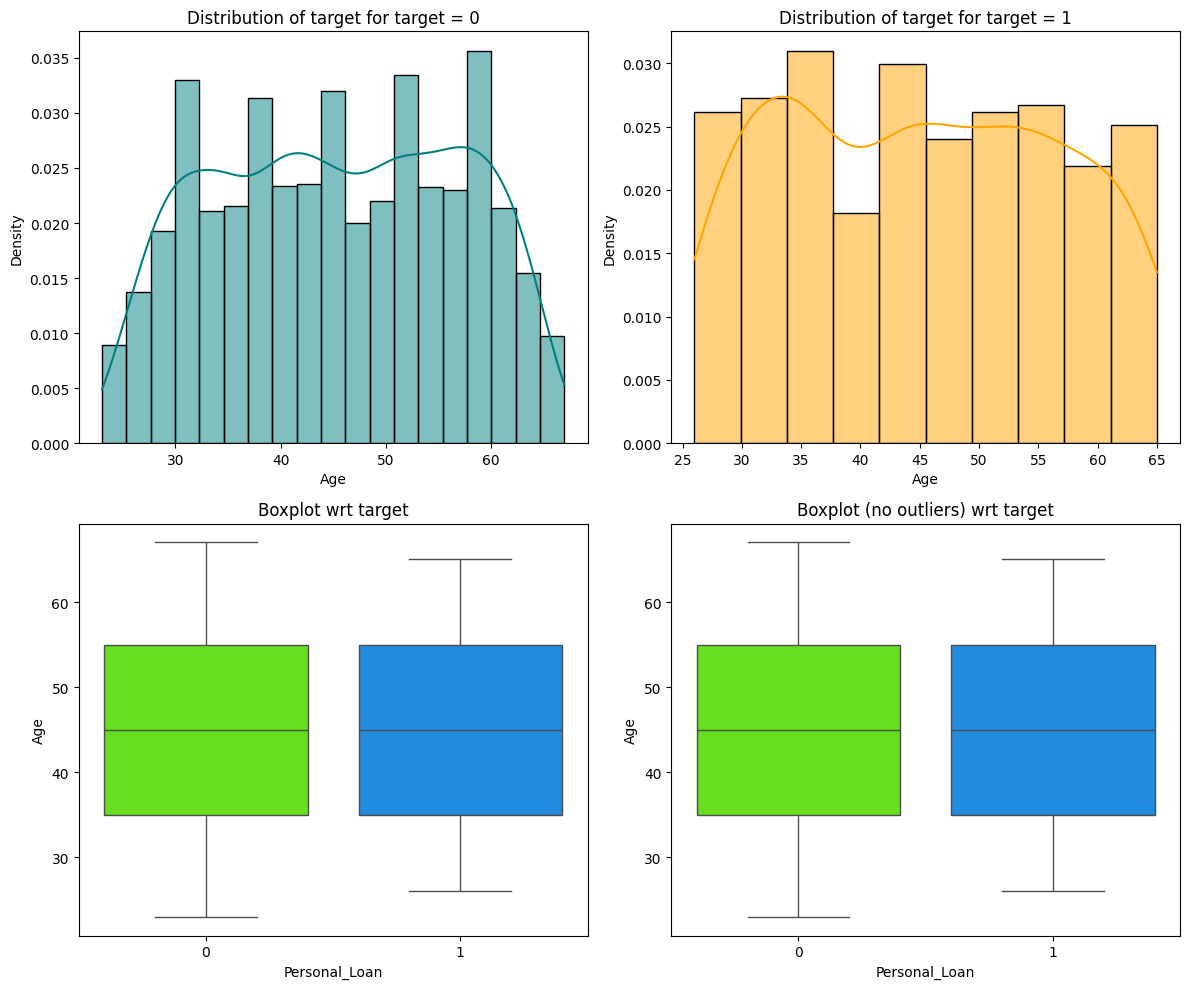

In [ ]:
# The histograms and boxplots for Age and Personal_Loan
dist_plot_wrt_target(df_copy, 'Age', 'Personal_Loan')

Both distributions appear to be somewhat symmetrical and similar.

#### Personal_Loan vs Experience

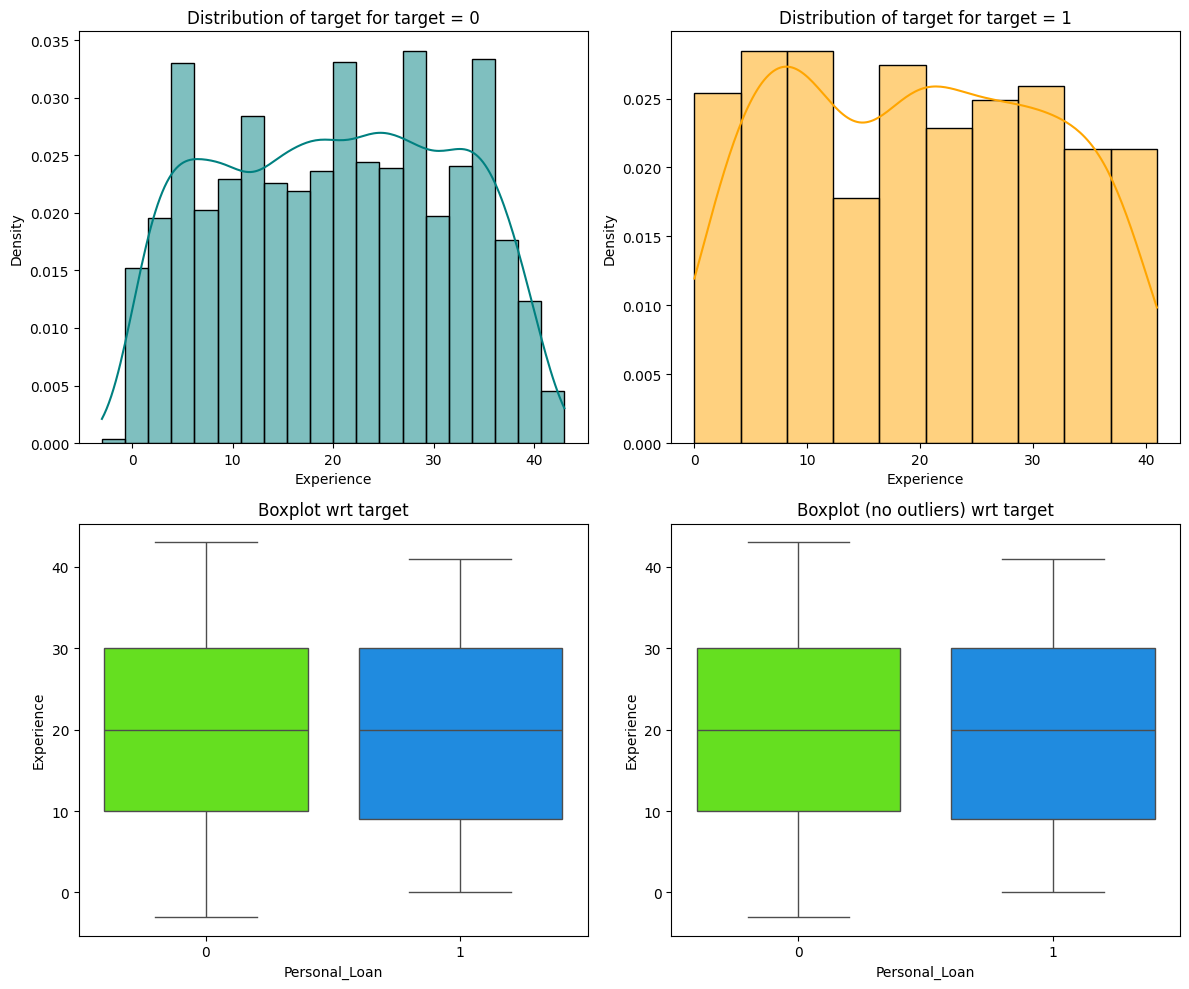

In [ ]:
# The histograms and boxplots for Experience and Personal_Loan
dist_plot_wrt_target(df_copy, 'Experience', 'Personal_Loan')

Both distributions appear to be somewhat symmetrical and similar.

#### Personal_Loan vs Income

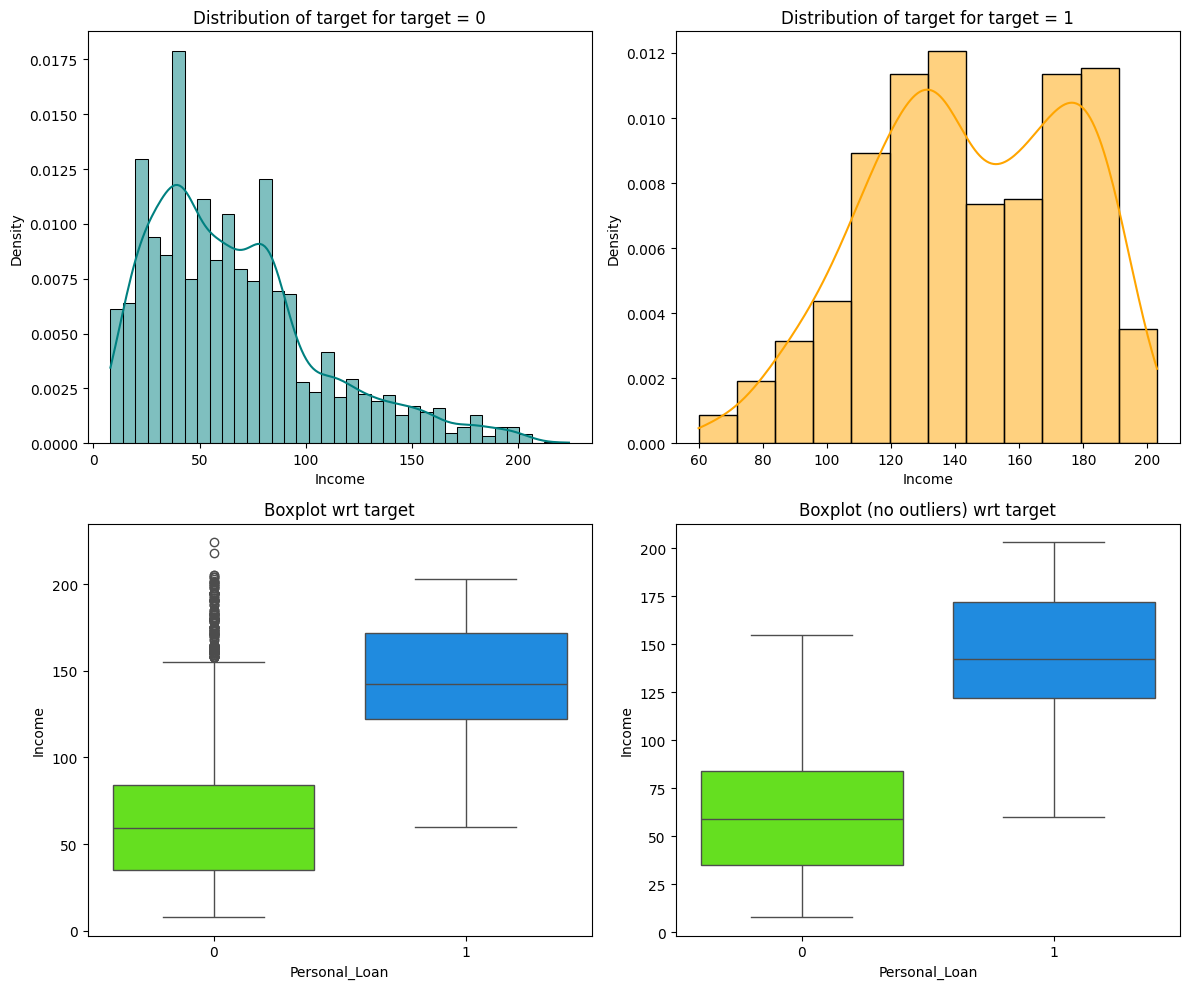

In [ ]:
# The histograms and boxplots for Income and Personal_Loan
dist_plot_wrt_target(df_copy, 'Income', 'Personal_Loan')

The distribution for those without personal loans appears to be right-skewed, while the one for those with personal loans appears to be left-skewed. Additionally, there are numerous outliers for those without personal loans.

#### Personal_Loan vs CCAvg

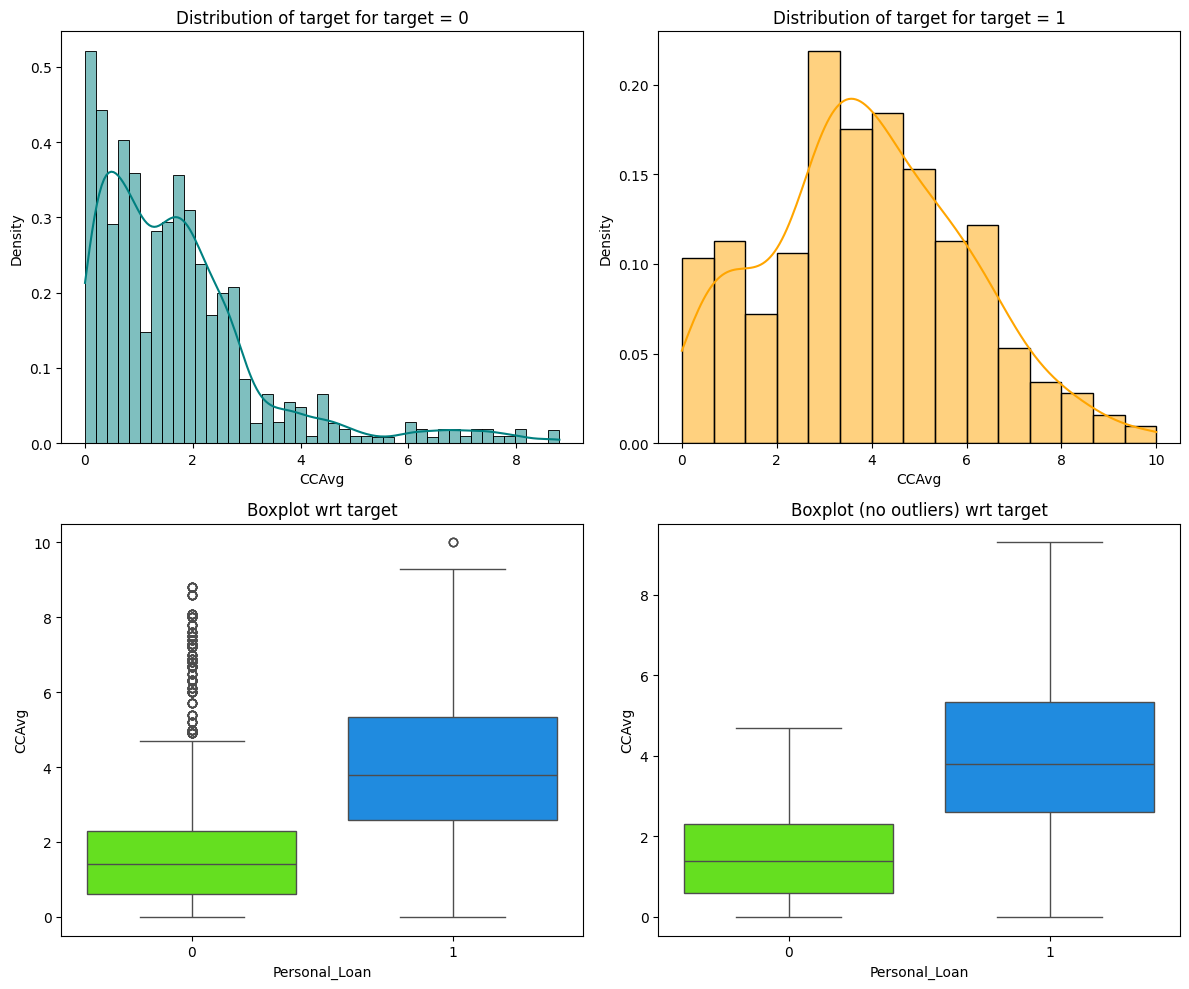

In [ ]:
# The histograms and boxplots for CCAvg and Personal_Loan
dist_plot_wrt_target(df_copy, 'CCAvg', 'Personal_Loan')

Both distributions appear to be right-skewed. Additionally, there are numerous outliers for those without personal loans.

## Data Preprocessing Part II

### Outlier Detection and Treatment

In [ ]:
# The 1st quartile, 3rd quartile, IQR, lower bound, and upper bound of the boxplot
q1 = df_copy.select_dtypes(include = ['float64', 'int64']).quantile(0.25)
q3 = df_copy.select_dtypes(include = ['float64', 'int64']).quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

In [ ]:
# Finding % of data that is outliers by col
(
    (df_copy.select_dtypes(include = ['float64', 'int64']) < lower)
    | (df_copy.select_dtypes(include = ['float64', 'int64']) > upper)
).sum() / len(df_copy) * 100

,0
Age,0.00
Experience,0.00
Income,1.92
Family,0.00
CCAvg,6.48
Mortgage,5.82


Income is 1.92% outliers, CCAvg is 6.48% outliers, and Mortgage is 5.82% outliers.

### Preparing Data for Modeling

In [ ]:
# Dropping Personal_Loan and Experience cols
X = df_copy.drop(['Personal_Loan', 'Experience'], axis = 1)
Y = df_copy['Personal_Loan']

X = pd.get_dummies(X, columns = ['ZIPCode', 'Education'], drop_first = True)
X = X.astype(float)

# Splitting data
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size = 0.3, random_state = 1
)

In [ ]:
# Printing shapes and % of classes
print('Train shape: ', X_train.shape)
print('Test shape: ', X_test.shape)
print('% of classes in training set:')
print(Y_train.value_counts(normalize = True))
print('% of classes in test set:')
print(Y_test.value_counts(normalize = True))

Train shape:  (3500, 17)
Test shape:  (1500, 17)
% of classes in training set:
Personal_Loan
0    0.905429
1    0.094571
Name: proportion, dtype: float64
% of classes in test set:
Personal_Loan
0    0.900667
1    0.099333
Name: proportion, dtype: float64


## Model Building

### Model Evaluation Criterion

In [ ]:
# The model_perform_class function
def model_perform_class(model, predictors, target):
  # Predicting using the independent variables
  pred = model.predict(predictors)

  # Computing accuracy, recall, precision, and f1
  acc = accuracy_score(target, pred)
  recall = recall_score(target, pred)
  precision = precision_score(target, pred)
  f1 = f1_score(target, pred)

  # A dataframe of metrics
  perf = pd.DataFrame(
    {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
    index=[0],
  )

  return perf

In [ ]:
# The my_confusion_matrix function
def my_confusion_matrix(model, predictors, target):
  y_pred = model.predict(predictors)
  cm = confusion_matrix(target, y_pred)
  labels = np.asarray(
    [
      ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
      for item in cm.flatten()
    ]
  ).reshape(2, 2)

  plt.figure(figsize = (6, 4))
  sns.heatmap(cm, annot = labels, fmt = "")
  plt.ylabel("True label")
  plt.xlabel("Predicted label")

### Model Building

In [ ]:
# The decision tree
model = DecisionTreeClassifier(criterion = "gini", random_state = 1)
model.fit(X_train, Y_train)

DecisionTreeClassifier(random_state=1)

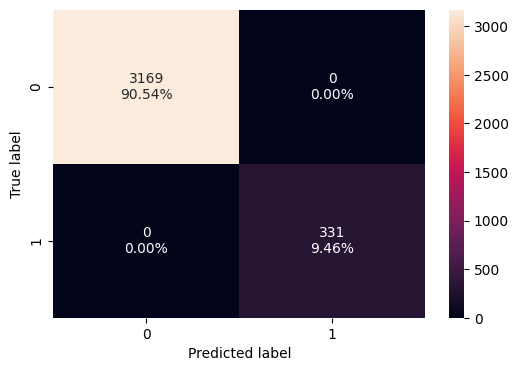

In [ ]:
# Model performance of training data
my_confusion_matrix(model, X_train, Y_train)

In [ ]:
# The accuracy, recall, precision, and f1 of training data
decision_tree_perf_train = model_perform_class(
  model, X_train, Y_train
)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [ ]:
# The decision tree itself
feature_names = list(X_train.columns)
print(feature_names)

['Age', 'Income', 'Family', 'CCAvg', 'Mortgage', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard', 'ZIPCode_91', 'ZIPCode_92', 'ZIPCode_93', 'ZIPCode_94', 'ZIPCode_95', 'ZIPCode_96', 'Education_2', 'Education_3']


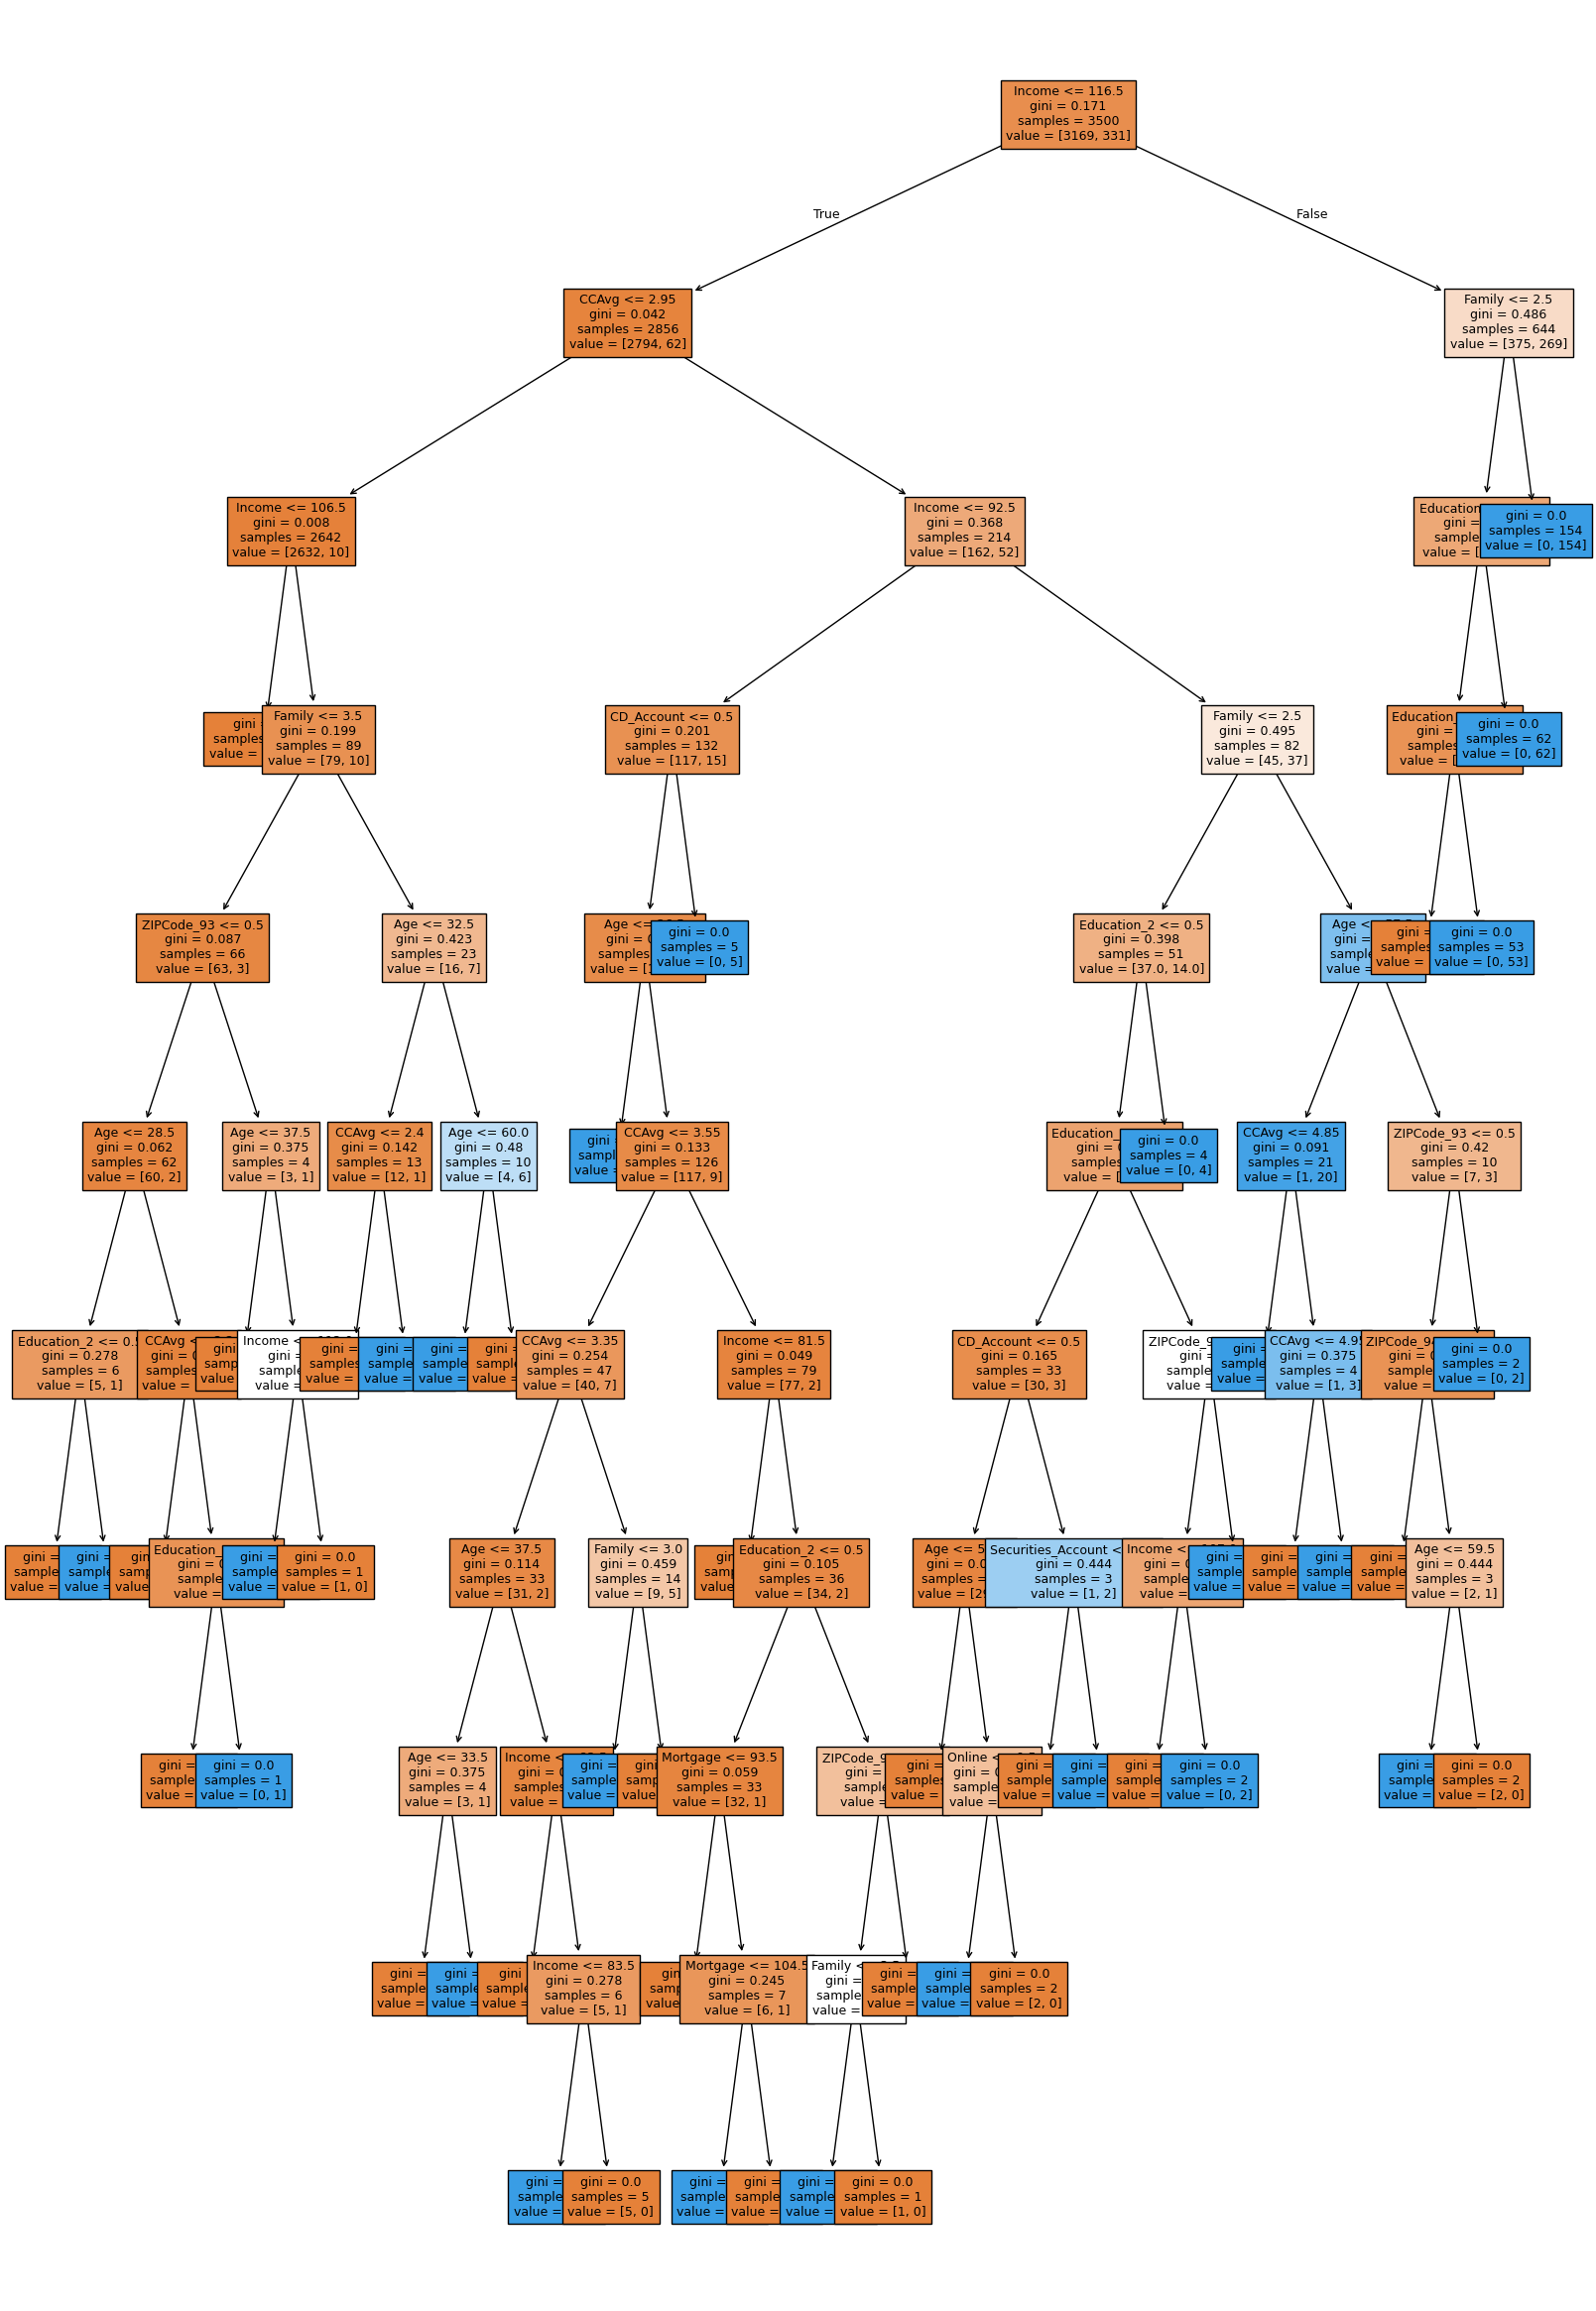

In [ ]:
plt.figure(figsize = (20, 30))
out = tree.plot_tree(
  model,
  feature_names = feature_names,
  filled = True,
  fontsize = 9,
  node_ids = False,
  class_names = None,
)
for o in out:
  arrow = o.arrow_patch
  if arrow is not None:
    arrow.set_edgecolor("black")
    arrow.set_linewidth(1)
plt.show()

In [ ]:
# Rules of the decision tree
print(tree.export_text(model, feature_names = feature_names, show_weights = True))

|--- Income <= 116.50
|   |--- CCAvg <= 2.95
|   |   |--- Income <= 106.50
|   |   |   |--- weights: [2553.00, 0.00] class: 0
|   |   |--- Income >  106.50
|   |   |   |--- Family <= 3.50
|   |   |   |   |--- ZIPCode_93 <= 0.50
|   |   |   |   |   |--- Age <= 28.50
|   |   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |   |--- weights: [5.00, 0.00] class: 0
|   |   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |   |--- Age >  28.50
|   |   |   |   |   |   |--- CCAvg <= 2.20
|   |   |   |   |   |   |   |--- weights: [48.00, 0.00] class: 0
|   |   |   |   |   |   |--- CCAvg >  2.20
|   |   |   |   |   |   |   |--- Education_3 <= 0.50
|   |   |   |   |   |   |   |   |--- weights: [7.00, 0.00] class: 0
|   |   |   |   |   |   |   |--- Education_3 >  0.50
|   |   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |--- ZIPCode_93 >  0.50
|   |   |   |   |   |--- Age <= 37.50

In [ ]:
# By importance
print(
  pd.DataFrame(
    model.feature_importances_, columns = ["Imp"], index = X_train.columns
  ).sort_values(by = "Imp", ascending = False)
)

                         Imp
Income              0.308098
Family              0.259255
Education_2         0.166192
Education_3         0.147127
CCAvg               0.048798
Age                 0.033150
CD_Account          0.017273
ZIPCode_94          0.007183
ZIPCode_93          0.004682
Mortgage            0.003236
Securities_Account  0.002224
Online              0.002224
ZIPCode_91          0.000556
CreditCard          0.000000
ZIPCode_92          0.000000
ZIPCode_96          0.000000
ZIPCode_95          0.000000


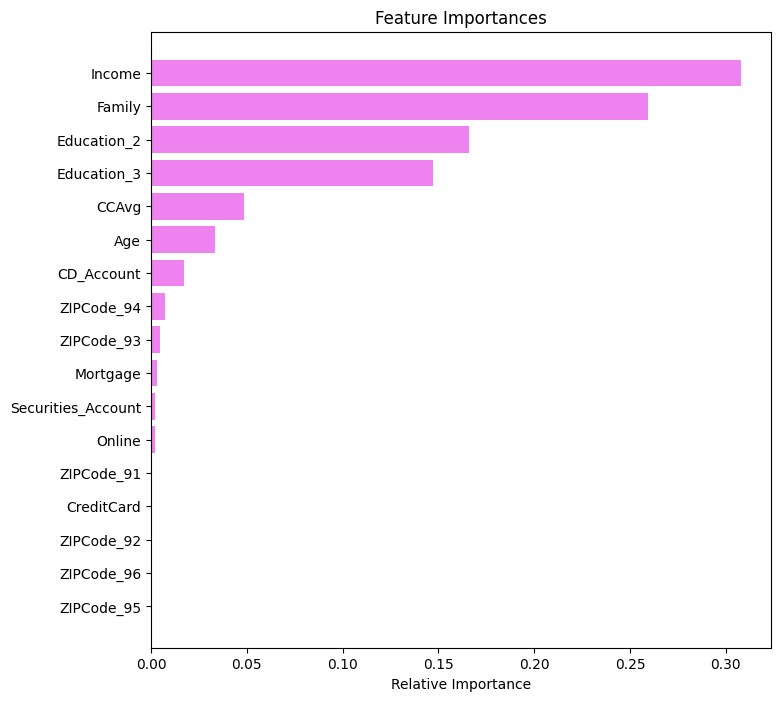

In [ ]:
# Barplot for feature importances
importances = model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color = "violet", align = "center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

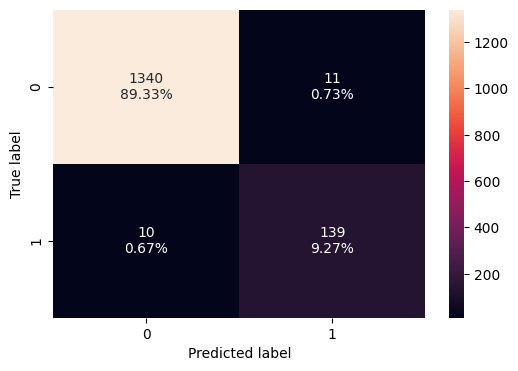

In [ ]:
# Model performance of test data
my_confusion_matrix(model, X_test, Y_test)

In [ ]:
# The accuracy, recall, precision, and f1 of test data
decision_tree_perf_test = model_perform_class(
  model, X_test, Y_test
)
decision_tree_perf_test

,Accuracy,Recall,Precision,F1
0,0.986,0.932886,0.926667,0.929766


The TP and TN appear to closely follow the training and test TPs and TNs, and the FP and FN appear to be minimal.

Additionally, the accuracy, recall, precision, and f1 are close to 1.0.

## Model Performance Improvement

### Pre-Pruning

In [ ]:
# Tree params
max_depth_values = np.arange(2, 7, 2)
max_leaf_nodes_values = [50, 75, 150, 250]
min_samples_split_values = [10, 30, 50, 70]

# Initializing variables
best_estimator = None
best_score_diff = float('inf')
best_test_score = 0.0

# Iterating over all combinations of the specified parameter values
for max_depth in max_depth_values:
  for max_leaf_nodes in max_leaf_nodes_values:
    for min_samples_split in min_samples_split_values:

      # Initializing the tree with the current set of parameters
      estimator = DecisionTreeClassifier(
        max_depth = max_depth,
        max_leaf_nodes = max_leaf_nodes,
        min_samples_split = min_samples_split,
        class_weight = 'balanced',
        random_state = 42
      )

      # Fitting the model to the training data
      estimator.fit(X_train, Y_train)

      # Making predictions on the training and test sets
      y_train_pred = estimator.predict(X_train)
      y_test_pred = estimator.predict(X_test)

      # Calculating recall scores for training and test sets
      train_recall_score = recall_score(Y_train, y_train_pred)
      test_recall_score = recall_score(Y_test, y_test_pred)

      # Calculating the absolute difference between training and test recall scores
      score_diff = abs(train_recall_score - test_recall_score)

      # Updating the best estimator and best score if the current one has a smaller score difference
      if (score_diff < best_score_diff) & (test_recall_score > best_test_score):
        best_score_diff = score_diff
        best_test_score = test_recall_score
        best_estimator = estimator

# Printing the best parameters
print("Best parameters:")
print(f"Max depth: {best_estimator.max_depth}")
print(f"Max leaf nodes: {best_estimator.max_leaf_nodes}")
print(f"Min samples split: {best_estimator.min_samples_split}")
print(f"Best test recall score: {best_test_score}")

Best parameters:
Max depth: 2
Max leaf nodes: 50
Min samples split: 10
Best test recall score: 1.0


In [ ]:
# Fitting best algorithm
estimator = best_estimator
estimator.fit(X_train, Y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(2),
                       max_leaf_nodes=50, min_samples_split=10,
                       random_state=42)

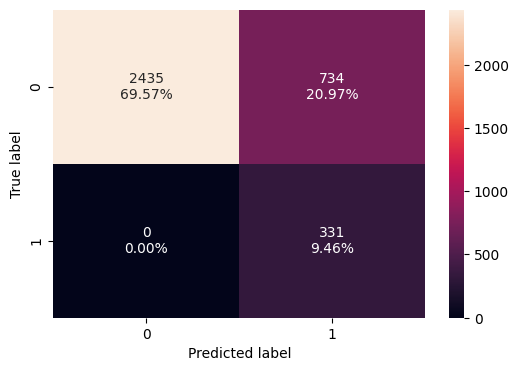

In [ ]:
# Model performance of pre-pruned training data
my_confusion_matrix(estimator, X_train, Y_train)

In [ ]:
# The accuracy, recall, precision, and f1 of pre-pruned training data
decision_tree_tune_perf_train = model_perform_class(
  estimator, X_train, Y_train
)
decision_tree_tune_perf_train

,Accuracy,Recall,Precision,F1
0,0.790286,1.0,0.310798,0.474212


After pre-pruning, the training TP is smaller than the original training TP, and the FP is larger than the original training FP.

Additionally, the accuracy is fairly high, the recall is perfect, and the precision and f1 score are low.

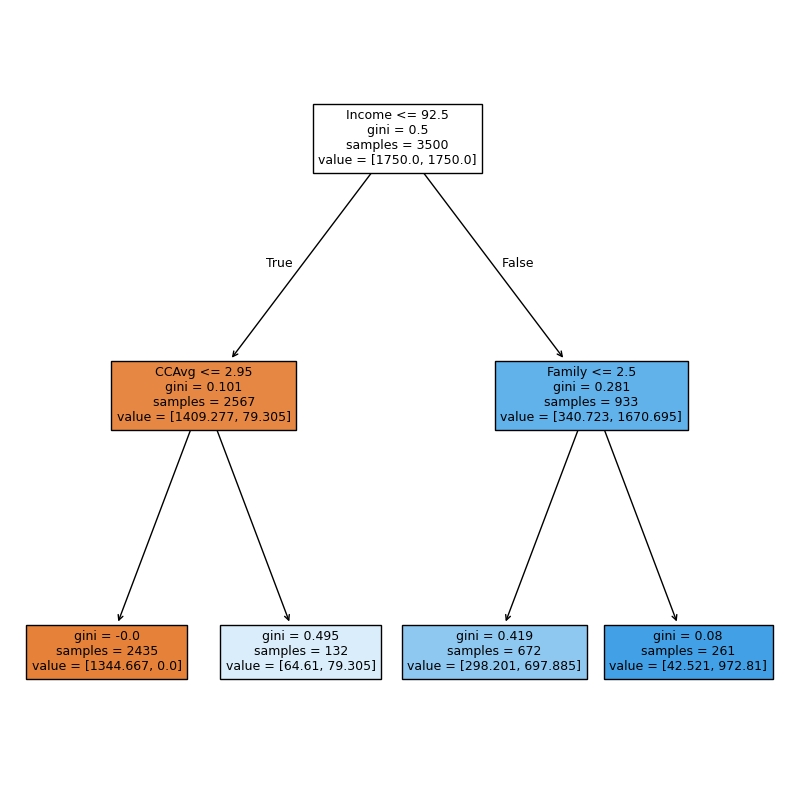

In [ ]:
# The decision tree
plt.figure(figsize = (10, 10))
out = tree.plot_tree(
  estimator,
  feature_names = feature_names,
  filled = True,
  fontsize = 9,
  node_ids = False,
  class_names = None,
)
for o in out:
  arrow = o.arrow_patch
  if arrow is not None:
    arrow.set_edgecolor("black")
    arrow.set_linewidth(1)
plt.show()

In [ ]:
# Rules of the decision tree
print(tree.export_text(estimator, feature_names = feature_names, show_weights = True))

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1344.67, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- weights: [64.61, 79.31] class: 1
|--- Income >  92.50
|   |--- Family <= 2.50
|   |   |--- weights: [298.20, 697.89] class: 1
|   |--- Family >  2.50
|   |   |--- weights: [42.52, 972.81] class: 1



In [ ]:
# By importance
print(
  pd.DataFrame(
    estimator.feature_importances_, columns=["Imp"], index=X_train.columns
  ).sort_values(by="Imp", ascending=False)
)

                         Imp
Income              0.876529
CCAvg               0.066940
Family              0.056531
Age                 0.000000
Mortgage            0.000000
Securities_Account  0.000000
CD_Account          0.000000
Online              0.000000
CreditCard          0.000000
ZIPCode_91          0.000000
ZIPCode_92          0.000000
ZIPCode_93          0.000000
ZIPCode_94          0.000000
ZIPCode_95          0.000000
ZIPCode_96          0.000000
Education_2         0.000000
Education_3         0.000000


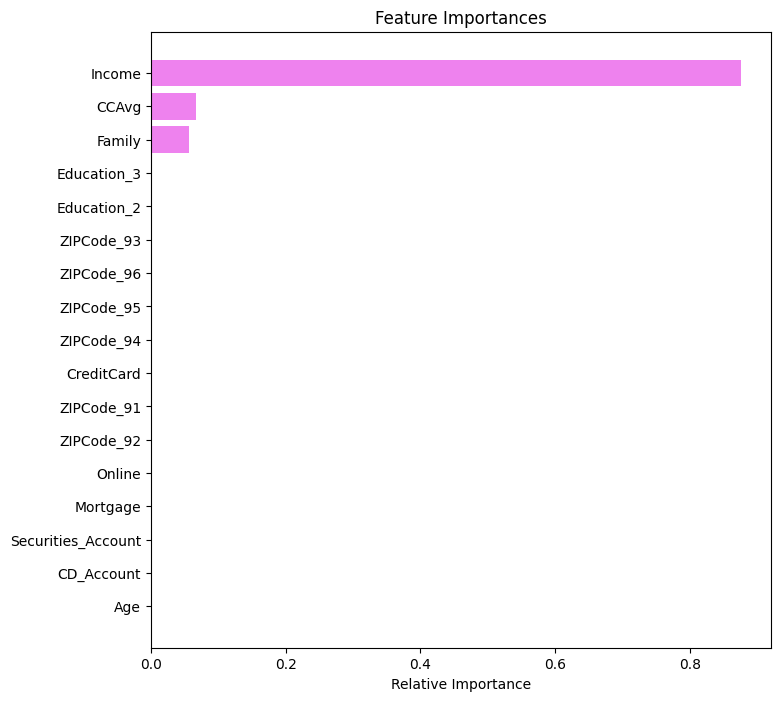

In [ ]:
importances = estimator.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color = "violet", align = "center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

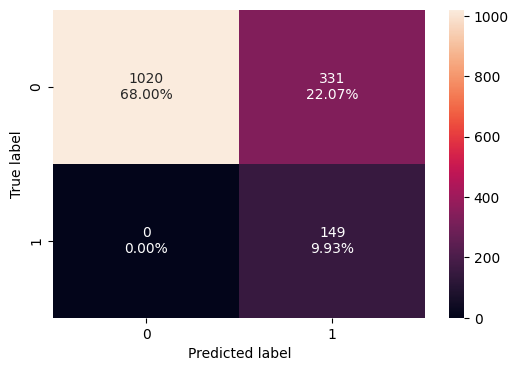

In [ ]:
# Model performance of pre-pruned test data
my_confusion_matrix(estimator, X_test, Y_test)

In [ ]:
# The accuracy, recall, precision, and f1 of pre-pruned training data
decision_tree_tune_perf_test = model_perform_class(
  estimator, X_test, Y_test
)
decision_tree_tune_perf_test

,Accuracy,Recall,Precision,F1
0,0.779333,1.0,0.310417,0.473768


After pre-pruning, the test TP is smaller than the original test TP, while the test FP is larger than the original test FP.

Additionally, the accuracy is fairly high, the recall is perfect, and the precision and f1 score are low.

### Post-Pruning

In [ ]:
# Defining the decision tree
clf = DecisionTreeClassifier(random_state = 1)
path = clf.cost_complexity_pruning_path(X_train, Y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

In [ ]:
# Storing path as a dataframe
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000,0.000000
1,0.000186,0.001114
2,0.000214,0.001542
3,0.000242,0.002750
4,0.000250,0.003250
5,0.000268,0.004324
6,0.000272,0.004868
7,0.000276,0.005420
8,0.000381,0.005801
9,0.000527,0.006329


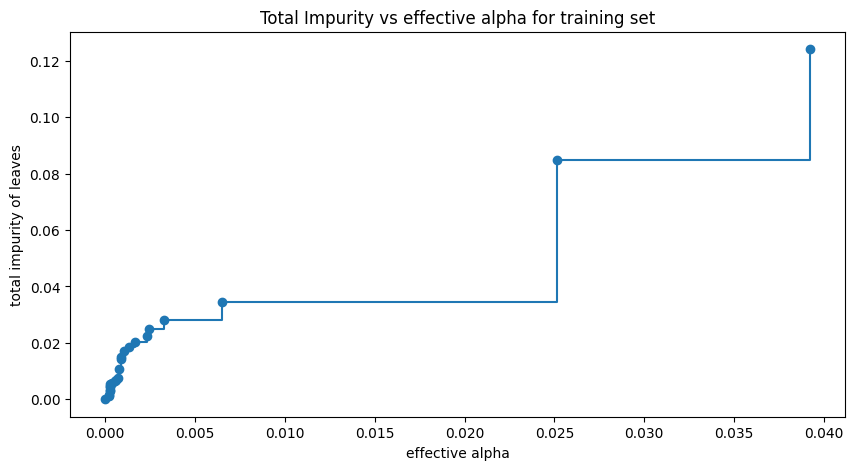

In [ ]:
# A graph of the effective alpha vs the total impurity of the leaves
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker = "o", drawstyle = "steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

It appears that as the effective alpha increases, so does the total impurity of the leaves.

In [ ]:
# Training decision tree with effective alphas
clfs = []
for ccp_alpha in ccp_alphas:
  clf = DecisionTreeClassifier(random_state = 1, ccp_alpha = ccp_alpha)
  clf.fit(X_train, Y_train)
  clfs.append(clf)
print(
  "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
    clfs[-1].tree_.node_count, ccp_alphas[-1]
  )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.04708834100596766


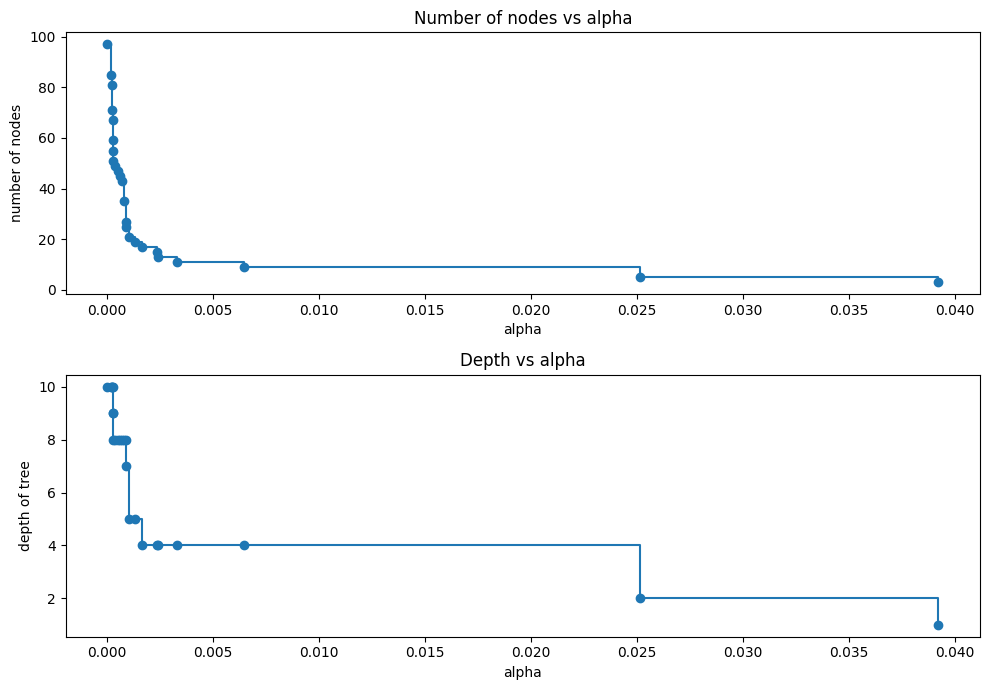

In [ ]:
# A graph of the alpha vs the depth of the tree and the number of nodes
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(ccp_alphas, node_counts, marker = "o", drawstyle = "steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

As the alpha increases, the depth of tree and the number of nodes decrease.

In [ ]:
# Training data recall
recall_train = []
for clf in clfs:
    pred_train = clf.predict(X_train)
    values_train = recall_score(Y_train, pred_train)
    recall_train.append(values_train)

# Test data recall
recall_test = []
for clf in clfs:
    pred_test = clf.predict(X_test)
    values_test = recall_score(Y_test, pred_test)
    recall_test.append(values_test)

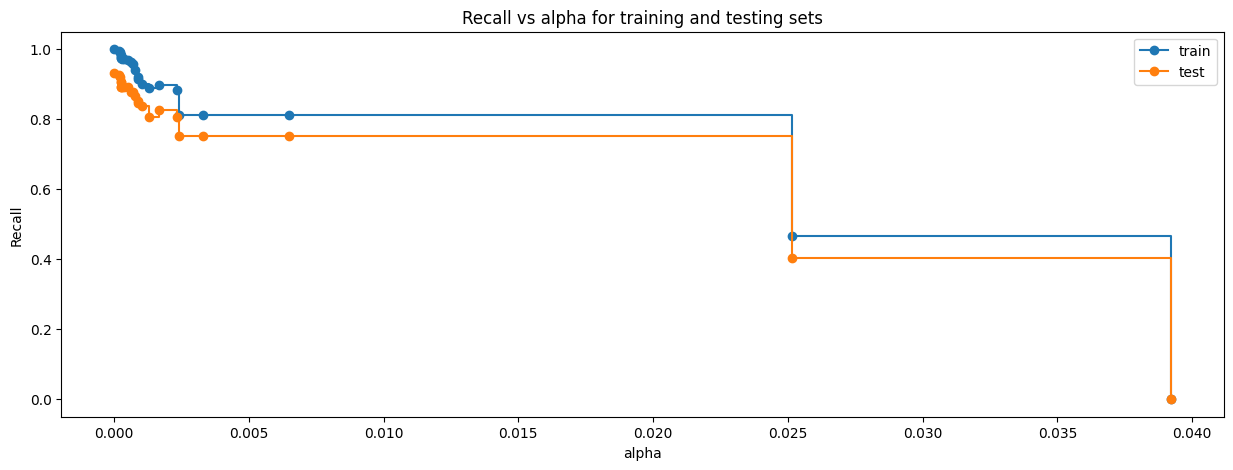

In [ ]:
# A plot of recall vs alpha for training and test
fig, ax = plt.subplots(figsize = (15, 5))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(ccp_alphas, recall_train, marker = "o", label = "train", drawstyle = "steps-post")
ax.plot(ccp_alphas, recall_test, marker = "o", label = "test", drawstyle = "steps-post")
ax.legend()
plt.show()

As the alpha increases for both the training and test data, the recall decreases.

In [ ]:
# The best model
index_best_model = np.argmax(recall_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(0.0), random_state=1)


In [ ]:
estimator_2 = DecisionTreeClassifier(
    ccp_alpha = 0.04708834100596766, class_weight = {0: 0.15, 1: 0.85}, random_state = 1
)
estimator_2.fit(X_train, Y_train)

DecisionTreeClassifier(ccp_alpha=0.04708834100596766,
                       class_weight={0: 0.15, 1: 0.85}, random_state=1)

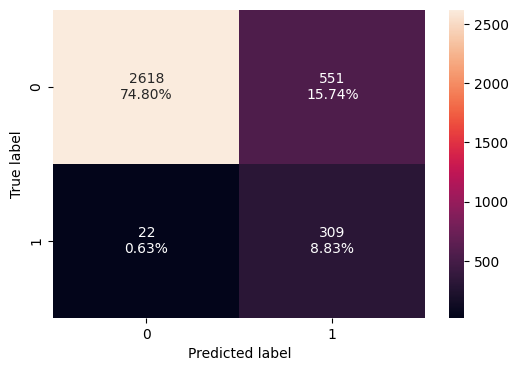

In [ ]:
# Model performance of post-pruned training data
my_confusion_matrix(estimator_2, X_train, Y_train)

In [ ]:
# The accuracy, recall, precision, and f1 of post-pruned training data
decision_tree_tune_post_train = model_perform_class(
  estimator_2, X_train, Y_train
)
decision_tree_tune_post_train

,Accuracy,Recall,Precision,F1
0,0.836286,0.933535,0.359302,0.518892


After post-pruning, the training TP is higher than the one for pre-pruning, but lower than the original TP. On the other hand, the training FP is lower than the one for pre-pruning, but higher than the original FP.

The FN still remains low, and the TN is lower than the TNs for pre-pruning and the original.

The accuracy is high, but the recall is a little lower and the precision and f1 are low.

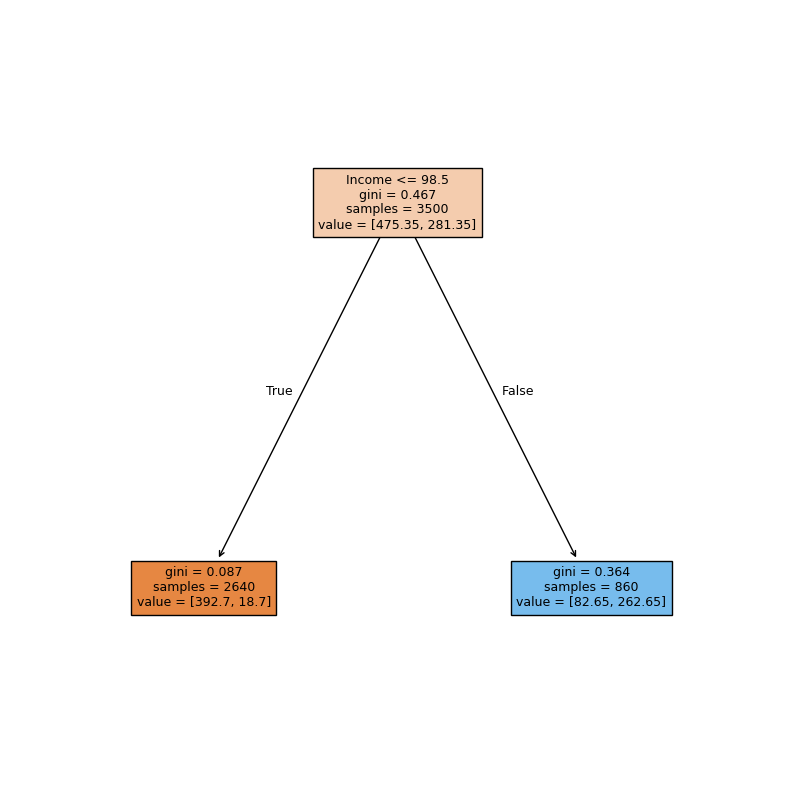

In [ ]:
# The decision tree
plt.figure(figsize = (10, 10))
out = tree.plot_tree(
  estimator_2,
  feature_names = feature_names,
  filled = True,
  fontsize = 9,
  node_ids = False,
  class_names = None,
)
for o in out:
  arrow = o.arrow_patch
  if arrow is not None:
    arrow.set_edgecolor("black")
    arrow.set_linewidth(1)
plt.show()

In [ ]:
# Rules of the decision tree
print(tree.export_text(estimator_2, feature_names = feature_names, show_weights = True))

|--- Income <= 98.50
|   |--- weights: [392.70, 18.70] class: 0
|--- Income >  98.50
|   |--- weights: [82.65, 262.65] class: 1



In [ ]:
# By importance
print(
  pd.DataFrame(
    estimator_2.feature_importances_, columns = ["Imp"], index = X_train.columns
  ).sort_values(by = "Imp", ascending = False)
)

                    Imp
Income              1.0
Age                 0.0
Family              0.0
CCAvg               0.0
Mortgage            0.0
Securities_Account  0.0
CD_Account          0.0
Online              0.0
CreditCard          0.0
ZIPCode_91          0.0
ZIPCode_92          0.0
ZIPCode_93          0.0
ZIPCode_94          0.0
ZIPCode_95          0.0
ZIPCode_96          0.0
Education_2         0.0
Education_3         0.0


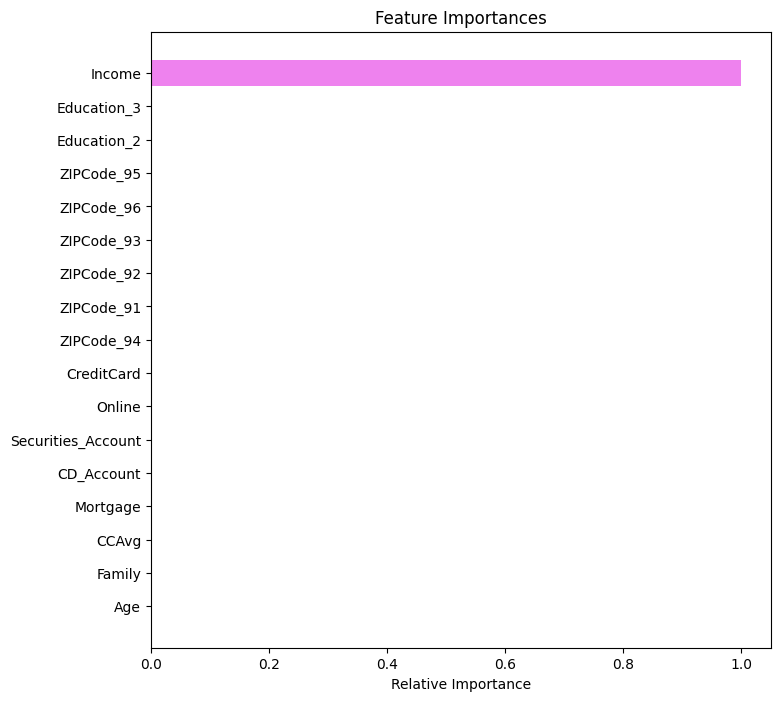

In [ ]:
importances = estimator_2.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color = "violet", align = "center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

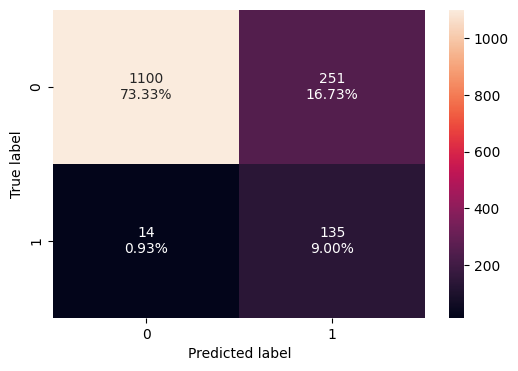

In [ ]:
# Model performance of post-pruned test data
my_confusion_matrix(estimator_2, X_test, Y_test)

In [ ]:
# The accuracy, recall, precision, and f1 of post-pruned test data
decision_tree_tune_post_test = model_perform_class(
  estimator_2, X_test, Y_test
)
decision_tree_tune_post_test

,Accuracy,Recall,Precision,F1
0,0.823333,0.90604,0.349741,0.504673


After post-pruning, the TP is lower than the pre-pruning and original TPs, while the FP is lower than the pre-pruning FP and higher than the original FP.

The accuracy and recall are high while the precision and f1 are low.

## Model Performance Comparison and Final Model Selection

In [ ]:
# Training performance comparison
models_train_comp_df = pd.concat(
    [decision_tree_perf_train.T, decision_tree_tune_perf_train.T, decision_tree_tune_post_train.T], axis = 1,
)
models_train_comp_df.columns = ["Decision Tree (Default)", "Decision Tree (Pre-Pruning)", "Decision Tree (Post-Pruning)"]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Decision Tree (Default),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,1.0,0.790286,0.836286
Recall,1.0,1.000000,0.933535
Precision,1.0,0.310798,0.359302
F1,1.0,0.474212,0.518892


In [ ]:
# Test performance comparison
models_test_comp_df = pd.concat(
    [decision_tree_perf_test.T, decision_tree_tune_perf_test.T, decision_tree_tune_post_test.T], axis = 1,
)
models_test_comp_df.columns = ["Decision Tree (Default)", "Decision Tree (Pre-Pruning)", "Decision Tree (Post-Pruning)"]
print("Test performance comparison:")
models_test_comp_df

Test performance comparison:


,Decision Tree (Default),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,0.986000,0.779333,0.823333
Recall,0.932886,1.000000,0.906040
Precision,0.926667,0.310417,0.349741
F1,0.929766,0.473768,0.504673


Post-pruning has a higher accuracy, precision, and f1 compared to pre-pruning in both training and test, while pre-pruning has a higher recall compared to post-pruning in both training and test. Between the two model performance improvement methods, post-pruning seems to be the more efficient option.

## Actionable Insights and Business Recommendations


What recommedations would you suggest to the bank?

Income appears to be the most salient feature in the data, and it also appears that those with lower incomes have the tendency to not have personal loans, while those with higher incomes have the tendency to have personal loans. The bank can attract the lower-income customers by offering them loans that fit within their income and spending.

___